# Creating selectors

This notebook explains the **selector contract** in full detail and
shows how to implement, validate and consume a custom selector.

Selectors are the objects that decide **which rows of the data receive
a deficit** (outlier / missing value / noise / drift / drop). A
generator that accepts a `selector` delegates the *who* to the selector
and keeps the *what* to itself.


## Goal

Write a custom selector: the index-only firing-spec contract (which rows a
deficit is applied to, keyed by column position), the preset implementations,
and how generators turn the specs into deficits.

## The contract

A selector is any callable with the signature:

```python
selector(X, targets=None) -> dict[int, spec]
```

The dict **keys are column positions** (ints) of `X` ? the columns the
deficit applies to; there is no `column_mapping` and no variable-name
lookup in the selector layer. Per target column, the returned **spec**
is one of:

* a **boolean mask** (`True` = deficit applied to that row) ? the
  value-free presets return firing decisions;
  * `AlwaysSelector` returns the constant scalar spec `1.0` per target
    (realizes to all-true) — `BernoulliSelector` and `ExactCountSelector` return
    boolean masks — and value-driven presets return `[0, 1]` firing specs;
* a **float in [0, 1]** (a scalar = one level for the whole column) or
  a **`(n,)` float array** ? the probability that the deficit is applied
  to that row (1.0 = definitely, 0.0 = never). A `(n,)` bool array is
  also a valid spec; a plain `bool` scalar is NOT (it is ambiguous ?
  use a mask).

The presets are self-contained: their `columns` (the positions they
cover, and the default call-time `targets`) and the column(s) they
READ (e.g. `class_column`, `column`, `driver`) are all bound at
construction as bare int positions. Nothing is passed at call time ?
so an intensity sweep means constructing a new selector.

*Exception:* a caller may pass `targets` explicitly at call time ?
`selector(X, targets=[...])`. Causal generators no longer take call-time
target arguments: the selector's `columns` (integer column positions)
ARE their intervention targets.

### How generators turn specs into deficits

A spec only says *how likely* each row is to be affected ? it does
not apply anything. Realizing it is the **consuming generator's** job,
and there is a single rule for every deficit type:

```python
fired = rng.random(n) < np.broadcast_to(spec, (n,))   # Bernoulli firing
```

(shape-preserving generators: noise, drift, missingness ? every row
keeps its place; a row with spec 0.3 is affected in 30% of the draws).
The helper `fired(X, selector, rng)` implements exactly this: it returns
the narrow boolean firing field of shape `(n_rows, n_targets)` where
column `i` belongs to the selector's `i`-th target, each column realized
with the single rule `rng.random(n) < spec`; row-level union is
`fired(X, selector, rng).any(axis=1)`.

*Row-removing* generators (imbalance) use the same realization to mark
the rows that are dropped: a boolean spec drops exactly its fired rows,
a fractional spec becomes the row's keep weight (`1 - score`) in the
resampling, so high-score rows disappear more often.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import default_rng

from badgers.core.selectors import AlwaysSelector, BernoulliSelector, ProportionalSelector

rng = default_rng(0)
X = rng.normal(size=(100, 2))

## Comparing the bundled selectors

All three bundled selectors below act on the **same single column**,
position 0 of `X`. The helper `_plot_selector_scores` draws one panel
per selector so they can be compared side by side on the same rows:
the first axis shows column 0 (sorted) as a reference for the row
order, the next three are the selectors applied to those rows.

| Selector | Spec type | What the panel shows |
|---|---|---|
| `AlwaysSelector([0])` | constant scalar spec `1.0`[^note-always] | every row affected |
| `BernoulliSelector([0], rate=0.3)` | bool mask | a random ~30% of rows |
| `ProportionalSelector([0], column=0)` | float spec | deficit probability rising with column 0 |

[^note-always]: value-free preset: the constant scalar spec `1.0` realizes to
  all-true, so every row is affected.

Bool masks draw red for affected rows, green for untouched ones;
float specs use a red-to-green colormap (red = high deficit
probability). Note the constructor order: every preset takes the
column positions it **covers** first, the positions it **reads**
(`column=`) after.

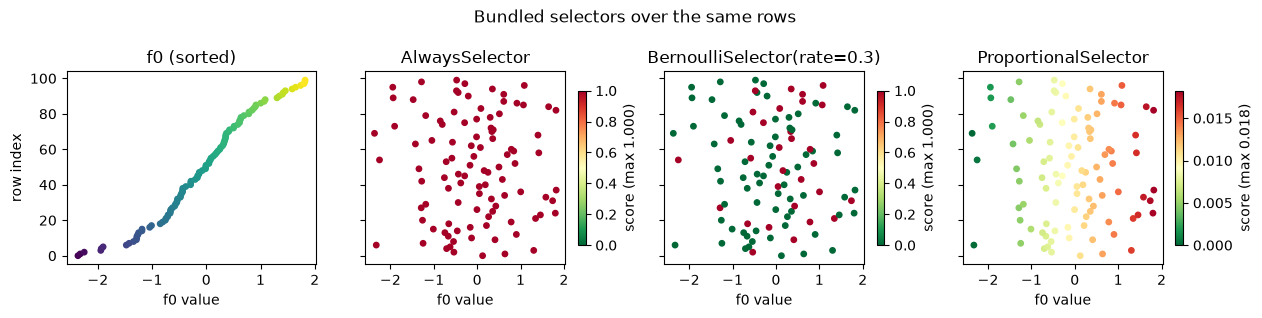

In [2]:
def _plot_selector_scores(selectors, X, title):
    """One panel per selector over X; bool masks drawn red/green,
    float scores with a red-to-green colormap. The first axis shows
    the f0 reference column."""
    n_sel = len(selectors)
    fig, axes = plt.subplots(1, n_sel + 1, figsize=(3.2 * (n_sel + 1), 3.2), sharex=True, sharey=True)
    f0 = X[:, 0]
    order = np.argsort(f0)
    axes[0].scatter(f0[order], np.arange(len(order)), c=f0[order], cmap='viridis', s=15)
    axes[0].set_title('f0 (sorted)')
    axes[0].set_xlabel('f0 value')
    axes[0].set_ylabel('row index')
    for ax, (name, sel) in zip(axes[1:], selectors):
        out = sel(X)
        if isinstance(out, dict):
            specs = [np.asarray(s, dtype=float) for s in out.values()]
            scores = np.broadcast_to(specs[0], (len(X),)) if specs[0].ndim == 0 else specs[0]
        else:
            scores = np.asarray(out, dtype=float)
        if scores.dtype == bool:
            colors = np.where(scores, 'C3', 'C2')
            ax.scatter(f0, np.arange(len(f0)), c=colors, s=15)
        else:
            # firing specs (float scalar or (n,) array) collapse a scalar
            # onto the 0..1 scale — scale per selector so the gradient is visible
            hi = scores.max()
            sc = ax.scatter(f0, np.arange(len(f0)), c=scores, cmap='RdYlGn_r', vmin=0, vmax=hi, s=15)
            fig.colorbar(sc, ax=ax, shrink=0.8, label=f'score (max {hi:.3f})')
        ax.set_title(name)
        ax.set_xlabel('f0 value')
    fig.suptitle(title)
    plt.tight_layout()
    return fig


_ = _plot_selector_scores(
    [('AlwaysSelector', AlwaysSelector([0])),
     ('BernoulliSelector(rate=0.3)', BernoulliSelector([0], rate=0.3, rng=default_rng(1))),
     ('ProportionalSelector', ProportionalSelector([0], column=0))],
    X,
    'Bundled selectors over the same rows')

## Building a custom selector

The minimal recipe ? a class with `__call__(self, X, targets=None)`
returning a `{column_position: spec}` dict. We build a *threshold*
selector: select rows whose reference column (an int position bound at
construction) exceeds a constructor-time threshold.

In [3]:
class ThresholdSelector:
    """Select rows whose reference column exceeds a fixed threshold.

    Returns a BOOLEAN mask (deterministic case of the contract).
    """

    def __init__(self, columns, column, threshold=0.0):
        self.columns = tuple(columns)
        self.column = int(column)
        self.threshold = threshold

    def __call__(self, X, targets=None):
        targets = self.columns if targets is None else tuple(targets)
        extra = [c for c in targets if c not in self.columns]
        if extra:
            raise ValueError(f"targets {extra} outside the selector's columns {self.columns}")
        col = X[:, self.column]
        return {c: col > self.threshold for c in targets}

    def __repr__(self):
        return (f"ThresholdSelector(columns={self.columns!r}, "
                f"column={self.column}, threshold={self.threshold})")


sel = ThresholdSelector([0], column=0, threshold=1.0)
X = default_rng(0).normal(size=(100, 2))
values = sel(X)
print(sel)
print('dtype:', values[0].dtype, '| affected:', int(values[0].sum()))

ThresholdSelector(columns=(0,), column=0, threshold=1.0)
dtype: bool | affected: 14


## A score-returning variant

Now the probabilistic flavor: instead of a mask we return the
probability that each row is affected. We make it a smooth function of the
reference column ? the further above the threshold, the closer to 1.0.
Notice the selector draws **no randomness**.

In [4]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


class SmoothThresholdSelector:
    """Scores: P(deficit) = sigmoid((col - threshold) / slope)."""

    def __init__(self, columns, column, threshold=0.0, slope=1.0):
        self.columns = tuple(columns)
        self.column = int(column)
        self.threshold = threshold
        self.slope = slope

    def __call__(self, X, targets=None):
        targets = self.columns if targets is None else tuple(targets)
        extra = [c for c in targets if c not in self.columns]
        if extra:
            raise ValueError(f"targets {extra} outside the selector's columns {self.columns}")
        col = X[:, self.column]
        scores = sigmoid((col - self.threshold) / self.slope)
        assert np.all((scores >= 0) & (scores <= 1))
        return {c: scores for c in targets}


sel = SmoothThresholdSelector([0], column=0, threshold=0.0, slope=0.5)
values = sel(X)[0]
print('range:', values.min(), '...', values.max())
print('monotone in reference column:', np.all(np.diff(values[np.argsort(X[:, 0])]) >= 0))

range: 0.008743976272339568 ... 0.9745192926928778
monotone in reference column: True


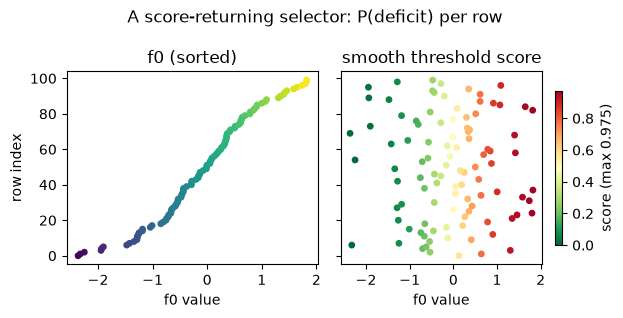

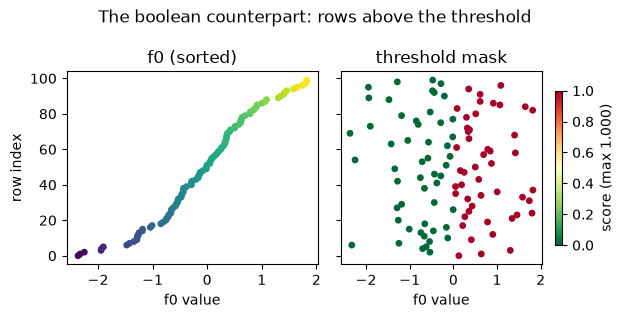

In [5]:
# visualize the score function
sel_smooth = SmoothThresholdSelector([0], column=0, threshold=0.0, slope=0.5)
_ = _plot_selector_scores(
    [('smooth threshold score', sel_smooth)],
    X,
    'A score-returning selector: P(deficit) per row')

# and, as the deterministic counterpart, the threshold mask
sel_mask = ThresholdSelector([0], column=0, threshold=0.0)
_ = _plot_selector_scores(
    [('threshold mask', sel_mask)],
    X,
    'The boolean counterpart: rows above the threshold')

## Consuming the selector with a real generator

Selectors are only useful through generators.

Below we use our `SmoothThresholdSelector` (float specs) with the
`RandomSamplingTargetsGenerator` and verify that the resampled rows skew toward
low-score rows.

In [6]:
from badgers.generators.tabular_data.imbalance import RandomSamplingTargetsGenerator

# A ROW-REMOVING generator: turns fractional specs into keep-weights.
# It resamples `size` rows with replacement, weighted by (1 - score):
# rows with a LOW deficit probability (score ~ 0) are likely kept/replicated,
# rows with a HIGH score (deficit) are under-sampled.
rng = default_rng(0)
sel = SmoothThresholdSelector([0], column=0, threshold=0.0, slope=0.5)
Xw = default_rng(1).normal(size=(200, 2))
gen = RandomSamplingTargetsGenerator(random_generator=rng)
Xt = gen.generate(Xw, selector=sel, size=100)

scores = sel(Xw)[0]
print('input rows:', len(Xw), '-> resampled rows:', len(Xt))
print('population mean f0:', Xw[:, 0].mean().round(3))
print('resampled mean f0: ', Xt[:, 0].mean().round(3), '(skewed toward low-score rows)')
assert Xt[:, 0].mean() < Xw[:, 0].mean()

input rows: 200 -> resampled rows: 100
population mean f0: -0.137
resampled mean f0:  -0.696 (skewed toward low-score rows)


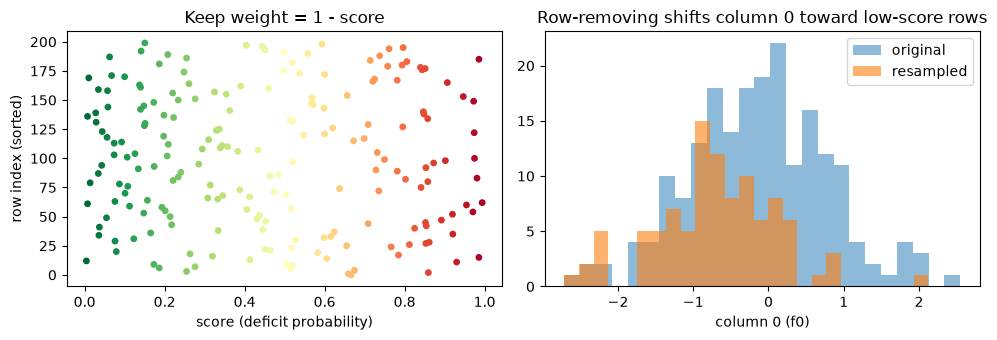

In [7]:
# viz: what the keep-weights did ? score vs keep probability, and
# the column-0 distribution before/after resampling
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(scores, np.arange(len(scores)), c=scores, cmap='RdYlGn_r', s=15)
axes[0].set_xlabel('score (deficit probability)')
axes[0].set_ylabel('row index (sorted)')
axes[0].set_title('Keep weight = 1 - score')
axes[1].hist(Xw[:, 0], bins=25, alpha=0.5, label='original')
axes[1].hist(Xt[:, 0], bins=25, alpha=0.6, label='resampled')
axes[1].set_xlabel('column 0 (f0)')
axes[1].set_title('Row-removing shifts column 0 toward low-score rows')
axes[1].legend()
plt.tight_layout()

## Conformance checklist

Before contributing a selector, check:

* [ ] constructor binds `columns` as int positions and every read column
  (`column`, `class_column`, `driver`, ...) as a bare int, and raises
  clearly on anything else;
* [ ] `__call__` accepts `(X, targets=None)` and validates call-time
  `targets` against the constructor `columns`;
* [ ] returned dict keys are exactly the resolved target positions;
* [ ] specs are bool masks or floats/(n,) arrays in [0, 1] ? never a
  plain `bool` scalar (assert internally);

## Takeaways

- A selector returns `dict[int, spec]`: keys are column positions; specs are
  bool masks (decisions) or floats in [0, 1] (deficit probabilities) ? never a
  bool scalar.
- Selectors never draw randomness for their rates; the consuming generator
  realizes every spec with the single rule `rng.random(n) < spec`.
- Presets are self-contained: constructor `columns` + read columns are int
  positions; an intensity sweep means constructing a new selector.